In [3]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2



NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3


const pes =  (2, 2, 2, 2)
const cuda = true
const numtrj_in = 2 # the number of operations to take average of performance
const MDsteps_in = 0 # dummy
PEs = pes

U= Initialize_Gaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot",cuda=true,blocks=PEs)

U1 = Initialize_Gaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
substitute_U!(U,U1)


x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t));



In [4]:
P=Onestep()
i=0.01
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)*i
W2=Generate_weight(hop)*i
W3=Generate_weight(hop)*i
W4=Generate_weight(hop)*i
W5=Generate_weight(hop)*i
W6=Generate_weight(hop)*i
W7=Generate_weight(hop)*i
W8=Generate_weight(hop)*i

layer1=CPTC_Layer(hop,W1)
Norm=NormLayer()
cNorm=complexNormLayer()
layer2=PTC_Layer(hop,W2 ,true)
act=Softmax()
layer4=PTC_Layer(hop,W4,true)
layer6=PTC_Layer(hop,W6,true)
layer8=PTC_Layer(hop,W8)

layer1=test_Layer(CPTC_Layer(hop,W1),sqrt(length(x)),t,act,true)
layer3=test_Layer(CPTC_Layer(hop,W3),sqrt(length(x)),t,act,true)
layer5=test_Layer(CPTC_Layer(hop,W5),sqrt(length(x)),t,act,true)
layer7=test_Layer(CPTC_Layer(hop,W7),sqrt(length(x)),t,act,true)

# layer1=HalfPAttention_Layer(layer1,sqrt(length(x)),t  , act,true,)
# layer3=HalfPAttention_Layer(CPTC_Layer(hop,W3), sqrt(length(x)),t, act,true)
# layer5=HalfPAttention_Layer(CPTC_Layer(hop,W5),sqrt(length(x)),t ,act,true)
# layer7=HalfPAttention_Layer(CPTC_Layer(hop,W7),sqrt(length(x)),t,act,true)

layers=[layer1];


In [5]:

xavier_init!(layer1.Q.W,length(x),length(x))
xavier_init!(layer1.K.W,length(x),length(x))
xavier_init!(layer1.V.W,length(x),length(x))
xavier_init!(layer3.Q.W,length(x),length(x))
xavier_init!(layer3.K.W,length(x),length(x))
xavier_init!(layer3.V.W,length(x),length(x))
xavier_init!(layer5.Q.W,length(x),length(x))
xavier_init!(layer5.K.W,length(x),length(x))
xavier_init!(layer5.V.W,length(x),length(x))
xavier_init!(layer7.Q.W,length(x),length(x))
xavier_init!(layer7.K.W,length(x),length(x))
xavier_init!(layer7.V.W,length(x),length(x))

xavier_init!(layer2.W,length(x),length(x))

xavier_init!(layer4.W,length(x),length(x))

xavier_init!(layer6.W,length(x),length(x))
xavier_init!(layer8.W,length(x),length(x))



params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.15
params["faster version"] = true
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den;







In [6]:



opt=Adam()
# opt.α=0.01





@time train(opt,layers,x,t,D,epochs=1)


┌ Warning: Performing scalar indexing on task Task (runnable, started) @0x0000016ebee25370.
│ Invocation of getindex resulted in scalar indexing of a GPU array.
│ This is typically caused by calling an iterating implementation of a method.
│ Such implementations *do not* execute on the GPU, but very slowly on the CPU,
│ and therefore should be avoided.
│ 
│ If you want to allow scalar iteration, use `allowscalar` or `@allowscalar`
│ to enable scalar iteration globally or for the operations in question.
└ @ GPUArraysCore C:\Users\_s2220186\.julia\packages\GPUArraysCore\aNaXo\src\GPUArraysCore.jl:145


LoadError: CUDA error: invalid argument (code 1, ERROR_INVALID_VALUE)

In [5]:
x1=Initialize_pseudofermion_fields(U1[1],"Wilson",nowing=true)
D1 = Dirac_operator(U1,x1,params)
t1=Initialize_pseudofermion_fields(U1[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x1)
gauss_distribution_fermion!(t1)

In [6]:
println(typeof(D1))

Wilson_Dirac_operator_faster{4, Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}, LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}}


In [7]:
cpuhop=Hopping_operator(U1,P)

Hopping_operator{Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}}(Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}[Gaugefields.AbstractGaugefields_module.Gaugefields_4D_nowing{3}(ComplexF64[0.5507382927170847 + 0.4776128979708735im 0.32303446831142957 - 0.04759043406114749im 0.3685181446017163 + 0.4755539008302494im; -0.41717724993675925 + 0.35174031075097106im -0.2037643459426688 + 0.21167634938686233im 0.7335445578402553 - 0.2789757911069791im; 0.3994379696005401 + 0.10613414623176431im -0.8582423764447817 + 0.26547527300267443im -0.09529702560412952 + 0.11422009917097509im;;; 0.1050583731431415 + 0.584373955513464im -0.18810360281517596 - 0.556057275008966im -0.2128555222800072 - 0.5075230896250171im; 0.6432441088700986 + 0.2771954319738309im 0.07174179332292185 + 0.26262321093464913im 0.6462089724505414 - 0.1330257004881199im; -0.3135408509427633 + 0.24199516944952817im -0.14186139681712973 + 0.7491160456029706im -0.17907309067084884 - 0.4793368286122

In [8]:
W1=Generate_weight(cpuhop)*i

9-element Vector{Spin_matrix}:
 [0.005028399624653235 + 0.0im 0.010131145397763443 + 0.0im 0.004671459982004953 + 0.0im -0.002600056064884415 + 0.0im; 0.013645522312355215 + 0.0im 0.005017824151145342 + 0.0im -0.007630952535449545 + 0.0im 0.004896581790739612 + 0.0im; -0.0011839327836545125 + 0.0im -0.01530683740854935 + 0.0im -0.008167384331869747 + 0.0im 0.010425269275871507 + 0.0im; 0.015692993655914002 + 0.0im -0.0005968860825206078 + 0.0im -0.005744143666968004 + 0.0im 0.00796976719009715 + 0.0im]
 [0.003981295189393063 + 0.0im -0.0052319020078874 + 0.0im -0.0011318077473436274 + 0.0im -0.00279507803885222 + 0.0im; 0.040331790542909196 + 0.0im -0.010453529761636863 + 0.0im 0.0017947998350465169 + 0.0im -0.007225942216993124 + 0.0im; 0.0022451599805144652 + 0.0im 0.004775807120361001 + 0.0im -0.019973940386196334 + 0.0im -0.003956997274323879 + 0.0im; 0.005468733631831391 + 0.0im 0.002288920875400898 + 0.0im -0.008835345580603254 + 0.0im 0.008834359717558624 + 0.0im]
 [-0.001455610

In [ ]:
layer1=CPTC_Layer(cpuhop,W1)
layer1=test_Layer(CPTC_Layer(cpuhop,W1),sqrt(length(x1)),t1,act,true)

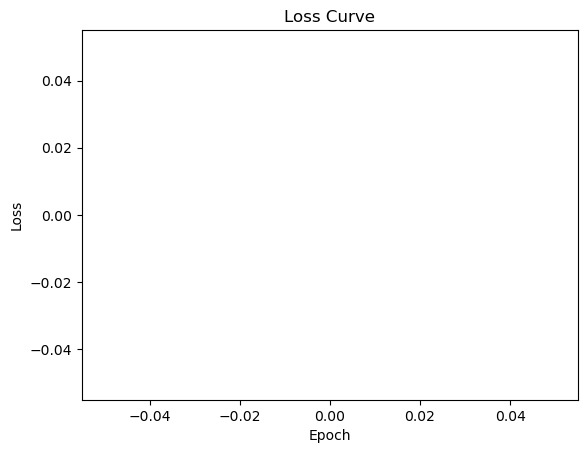

  1.242714 seconds (946.28 k allocations: 1.143 GiB, 6.20% gc time, 76.70% compilation time)
  0.002354 seconds (30 allocations: 9.002 MiB)
  4.353821 seconds (1.86 M allocations: 4.561 GiB, 17.73% gc time, 48.97% compilation time)
Epoch: 1, Loss: 133.58264108904035 + 0.0im
  7.570457 seconds (3.85 M allocations: 5.793 GiB, 11.53% gc time, 65.65% compilation time)


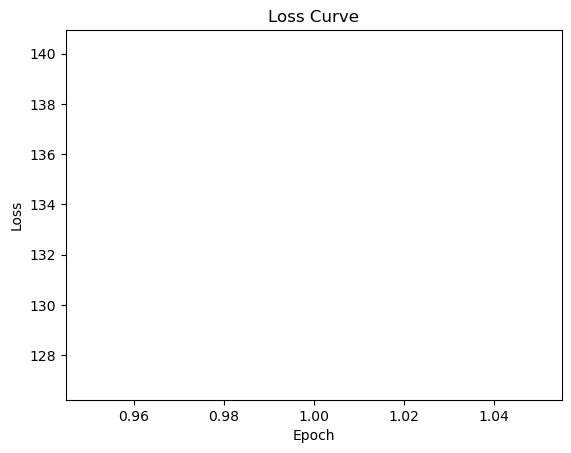

In [ ]:
@time train(opt,[layer1],x1,t1,D1,epochs=1)

In [ ]:
a=Random_SpinM_GPU()

4×4 Spin_matrix_GPU:
  0.866946-1.15604im     0.718191+0.0823553im  …   0.619837+0.3004im
  0.368749+1.70401im     0.561708-0.745155im      -0.195815-0.344017im
 -0.871363-0.762926im    0.325036-1.0072im        -0.278647+0.212859im
 -0.131785-0.0803278im  -0.682135-0.926378im       0.317621-0.307462im

In [ ]:
b=Random_SpinM()

4×4 Spin_matrix:
 0.450401+1.78421im   -0.517779+1.1225im     …   0.94059-1.13579im
 -2.17566+1.13788im    -1.31657-0.0317267im     0.770386+0.296429im
 0.359455-0.382601im   0.274476-1.29301im        1.61063+1.03713im
  1.62484+0.741318im   -1.55252+1.20323im        1.08763-1.66107im

In [ ]:
@time for i in 1:100
    x=a*x
end 

  0.145648 seconds (11.39 k allocations: 312.927 MiB, 5.04% gc time)


In [ ]:
println(typeof(a))

Spin_matrix_GPU


In [ ]:
@time for i in 1:100
    x1=b*x1
end

  0.095747 seconds (1.10 k allocations: 300.089 MiB, 18.59% gc time)


In [ ]:
@time for i in 1:1000
    a+=a
end 

  0.037086 seconds (108.14 k allocations: 7.133 MiB, 97.85% compilation time)


In [ ]:
@time for i in 1:1000
    b+=b
end

  0.000282 seconds (5.00 k allocations: 1000.000 KiB)


In [ ]:
using StaticArrays

a = @MMatrix rand(4,4)
b = @MMatrix rand(4,4)

@time a + b  # MMatrix 덧셈

A = rand(4,4)
B = rand(4,4)

@time A + B  # 일반 Matrix 덧셈


  0.013891 seconds (38.84 k allocations: 2.662 MiB, 99.50% compilation time)
  0.000019 seconds (1 allocation: 192 bytes)


4×4 Matrix{Float64}:
 1.82618   1.77521   0.839566  1.43591
 0.940641  0.806824  0.895563  0.896341
 0.274572  0.969606  1.72495   1.7474
 0.214899  1.30032   0.98863   1.10963